# RAG with LangChain — On-Call Troubleshooting Assistant

Self-contained notebook (all pipeline code inlined). Builds a LangChain RAG system
over the *Contoso Platform Troubleshooting Runbook* PDF.

Parts: **1** load/clean/chunk · **2** embeddings + FAISS · **3** top-k retrieval ·
**4** grounded LCEL answer chain · **5** end-to-end Q&A.

Runs with no API keys (offline fallback)


In [1]:
%pip install -q langchain langchain-community langchain-text-splitters langchain-huggingface sentence-transformers faiss-cpu pypdf matplotlib
# Optional LLM providers:
%pip install -q langchain-openai langchain-google-genai langchain-ollama


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, re, json

CANDIDATES = [
    os.environ.get("RUNBOOK_PDF", ""),
    "troubleshooting_runbook.pdf",
    "../troubleshooting_runbook.pdf",
]
PDF_PATH = next((p for p in CANDIDATES if p and os.path.exists(p)), None)
assert PDF_PATH, "Place troubleshooting_runbook.pdf next to this notebook or set RUNBOOK_PDF."
LLM_PROVIDER = os.environ.get("LLM_PROVIDER", "fallback")
print("PDF:", os.path.abspath(PDF_PATH), "| provider:", LLM_PROVIDER)


PDF: c:\Users\308843\Downloads\Learn\troubleshooting_runbook.pdf | provider: fallback


## Part 1 — Load, Explore, Chunk
`PyPDFLoader` (one Document per page) → clean text → `RecursiveCharacterTextSplitter`.


In [3]:
from langchain_community.document_loaders import PyPDFLoader

def clean_text(text: str) -> str:
    if not text:
        return ""
    text = re.sub(r"(\w)-\n(\w)", r"\1\2", text)      # de-hyphenate line breaks
    text = re.sub(r"(?<!\n)\n(?!\n)", " ", text)         # join intra-paragraph newlines
    text = re.sub(r"[ \t]+", " ", text)
    text = text.replace("\x0c", " ").strip()
    return re.sub(r"\n{3,}", "\n\n", text)

def page_label(doc):
    md = doc.metadata or {}
    if "page_label" in md: return md["page_label"]
    if "page" in md:       return md["page"] + 1
    return "?"

# Task 1 & 2 — load + extract text from all pages
docs = PyPDFLoader(PDF_PATH).load()
for d in docs:
    d.page_content = clean_text(d.page_content)
print(f"Loaded {len(docs)} pages.\n")
print(docs[0].page_content[:400])


C:\Users\308843\AppData\Local\Temp\ipykernel_10064\830561088.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


Loaded 7 pages.

Contoso Platform Engineering | Troubleshooting Runbook v3.2 | Internal - Synthetic demo data Page 1 Contoso Platform Troubleshooting Runbook Document owner: Platform Reliability Team | Version: 3.2 | Last reviewed: 2026-10-15 1. Purpose and scope This runbook gives on-call engineers a consistent way to diagnose and resolve production incidents across the eight core Contoso services: payment-gatewa


Task 3 — document structure & text-quality check:

In [4]:
def structure_report(docs):
    char_counts = [len(d.page_content) for d in docs]
    empty = [page_label(d) for d in docs if len(d.page_content.strip()) < 20]
    joined = "\n".join(d.page_content for d in docs)
    issues = []
    if empty: issues.append("Pages with little/no extractable text (possible images).")
    if re.search(r"Page \d+", joined): issues.append("Header/footer text interleaved with body.")
    if not issues: issues.append("No major issues after cleaning.")
    return {"num_pages": len(docs), "total_characters": sum(char_counts),
            "avg_chars_per_page": round(sum(char_counts)/max(1,len(docs)), 1),
            "empty_or_image_pages": empty, "quality_issues": issues}

print(json.dumps(structure_report(docs), indent=2))


{
  "num_pages": 7,
  "total_characters": 16550,
  "avg_chars_per_page": 2364.3,
  "empty_or_image_pages": [],
  "quality_issues": [
    "Header/footer text interleaved with body."
  ]
}


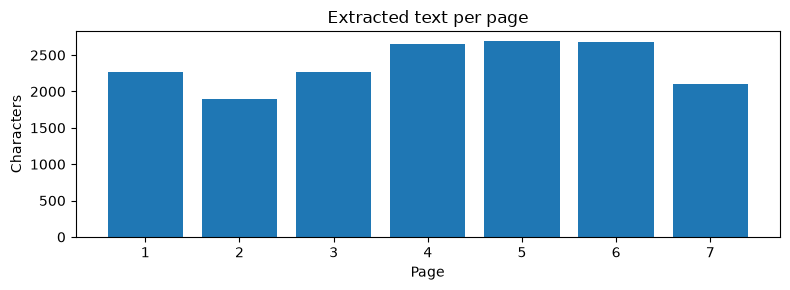

In [5]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,3))
plt.bar([str(page_label(d)) for d in docs], [len(d.page_content) for d in docs])
plt.xlabel("Page"); plt.ylabel("Characters"); plt.title("Extracted text per page")
plt.tight_layout(); plt.show()


Task 4 — chunking (`chunk_size=800`, `overlap=120` chars); each chunk keeps its page number.


In [6]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter = RecursiveCharacterTextSplitter(
    chunk_size=800, chunk_overlap=120,
    separators=["\n\n", "\n", ". ", " ", ""], add_start_index=True,
)
chunks = splitter.split_documents(docs)
for c in chunks:
    c.metadata["page_num"] = page_label(c)
print(f"{len(chunks)} chunks. Example (page {chunks[6].metadata['page_num']}):\n")
print(chunks[6].page_content[:350], "...")


28 chunks. Example (page 2):

. 5. Post the first update in #incidents with service, code, severity, owner. 8. Useful commands kubectl get pods -n prod -l app=<service> -o wide kubectl logs deploy/<service> -n prod --since=30m | grep -i error kubectl describe pod <pod> -n prod | grep -A5 "Last State" kubectl rollout undo deploy/<service> -n prod Rollback note: kubectl rollout u ...


## Part 2 — Embeddings + Vector DB
`all-MiniLM-L6-v2` (local, normalised → cosine) + `FAISS`.


In [7]:
try:
    from langchain_huggingface import HuggingFaceEmbeddings
except ImportError:
    from langchain_community.embeddings import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS

embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2",
    encode_kwargs={"normalize_embeddings": True},
)
vectorstore = FAISS.from_documents(chunks, embeddings)
vectorstore.save_local("faiss_runbook_index")
print("Indexed", vectorstore.index.ntotal, "chunks.")


c:\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Could not reach the Hub ([SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: unable to get local issuer certificate (_ssl.c:1028)). Using cached commit hash for 'sentence-transformers/all-MiniLM-L6-v2'.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1928.78it/s]
'[SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: unable to get local issuer certificate (_ssl.c:1028)' thrown while requesting HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/2_Normalize/config.json
Retrying in 1s [Retry 1/5].
'[SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: unable to get local issuer certificate (_ssl.c:1028)' thrown while requesting HEAD https://huggingface.co/sentence-t

Indexed 28 chunks.


Example retrieved chunks for a sample query:

In [8]:
for doc, score in vectorstore.similarity_search_with_score("How do I fix a gateway timeout?", k=3):
    print(f"[p.{doc.metadata['page_num']}] dist={score:.3f}  {doc.page_content[:140].strip()}...")


[p.4] dist=1.032  . Diagnostics: 1. Check the vendor status page. 2. Test connectivity from a debug pod (curl with timing). 3. Confirm circuit breaker state a...
[p.3] dist=1.039  . Most common on notification-service (burst campaigns) and auth-service (login storms). Throttling is enforced at the API gateway using a t...
[p.4] dist=1.296  Contoso Platform Engineering | Troubleshooting Runbook v3.2 | Internal - Synthetic demo data Page 4 Application and Gateway Errors ERR-500 -...


## Part 3 — Retrieval (top-k, k = 3/4/6)

In [9]:
query = "What causes DB-POOL connection pool exhaustion?"
for k in (3, 4, 6):
    hits = vectorstore.as_retriever(search_kwargs={"k": k}).invoke(query)
    print(f"k={k}:", ", ".join(f"p.{d.metadata['page_num']}" for d in hits))


k=3: p.5, p.5, p.4
k=4: p.5, p.5, p.4, p.5
k=6: p.5, p.5, p.4, p.5, p.7, p.3


Small `k` (3–4) returns the exact section; larger `k` adds coverage for multi-part questions. Default: **k = 4**.


## Part 4 — Grounded Answers (LCEL)
System prompt: answer only from context, cite pages like `[p.4]`, refuse if absent. Chain:
`retriever → format_docs → ChatPromptTemplate → LLM → StrOutputParser`, returning answer + sources.


In [10]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableLambda, RunnablePassthrough

SYSTEM_PROMPT = """You are the Contoso On-Call Troubleshooting Assistant. Answer using ONLY the runbook context provided.
Rules:
1. Use ONLY the context; no outside knowledge.
2. If the answer is not in the context, reply exactly: "That isn't covered in the runbook."
3. Be precise: give the error code, diagnostics, and fix in order when relevant.
4. Cite page number(s) like [p.4]. Never invent facts, commands, or pages."""

PROMPT = ChatPromptTemplate.from_messages([
    ("system", SYSTEM_PROMPT),
    ("human", "Runbook context:\n\n{context}\n\nQuestion: {question}\n\nAnswer (grounded, with page citations):"),
])

def format_docs(docs):
    return "\n\n---\n\n".join(f"[p.{d.metadata.get('page_num', page_label(d))}] {d.page_content}" for d in docs)

def _extractive_fallback(prompt_value):
    text = prompt_value.to_string() if hasattr(prompt_value, "to_string") else str(prompt_value)
    context = text.split("Runbook context:")[-1].split("Question:")[0]
    sentences = [s.strip() for s in re.split(r"(?<=[.!?])\s+", context) if len(s.strip()) > 40]
    pages = re.findall(r"\[p\.([\w-]+)\]", context)
    cite = f" [p.{pages[0]}]" if pages else ""
    picked = " ".join(sentences[:3]) if sentences else "No relevant context found."
    return f"(Extractive fallback.) Based on the runbook:{cite} {picked}"

def get_llm(provider="fallback", model=None, temperature=0.0):
    if provider == "openai":
        from langchain_openai import ChatOpenAI
        return ChatOpenAI(model=model or "gpt-4o-mini", temperature=temperature)
    if provider == "gemini":
        from langchain_google_genai import ChatGoogleGenerativeAI
        return ChatGoogleGenerativeAI(model=model or "gemini-1.5-flash", temperature=temperature)
    if provider == "ollama":
        from langchain_ollama import ChatOllama
        return ChatOllama(model=model or "llama3.1", temperature=temperature)
    return RunnableLambda(_extractive_fallback)


In [11]:
retriever = vectorstore.as_retriever(search_kwargs={"k": 4})
llm = get_llm(LLM_PROVIDER)

answer_chain = (RunnablePassthrough.assign(context=lambda x: format_docs(x["context"])) | PROMPT | llm | StrOutputParser())
rag_chain = RunnablePassthrough.assign(context=lambda x: retriever.invoke(x["question"])).assign(answer=answer_chain)

out = rag_chain.invoke({"question": "How do I diagnose and fix ERR-504 gateway timeouts?"})
print(out["answer"])
print("\nSources:", ", ".join(f"p.{d.metadata['page_num']}" for d in out["context"]))


(Extractive fallback.) Based on the runbook: [p.4] Test connectivity from a debug pod (curl with timing). Confirm circuit breaker state and failure threshold. Look for DNS resolution failures in the sidecar logs.

Sources: p.4, p.3, p.4, p.4


Sample queries (incl. an out-of-scope one that should be refused):

In [12]:
samples = [
    "What is the ack target and escalation path for a Sev1 incident?",
    "A container is OOMKilled with exit code 137 - what do I do?",
    "What should I check in the first five minutes of an incident?",
    "How do I reset my Gmail password?",   # not in the runbook -> refuse
]
for q in samples:
    out = rag_chain.invoke({"question": q})
    print("Q:", q)
    print("A:", out["answer"])
    print("Sources:", ", ".join(f"p.{d.metadata['page_num']}" for d in out["context"]), "\n")


Q: What is the ack target and escalation path for a Sev1 incident?
A: (Extractive fallback.) Based on the runbook: [p.2] [p.2] Contoso Platform Engineering | Troubleshooting Runbook v3.2 | Internal - Synthetic demo data Page 2 Severity and Escalation 5. Severity matrix Severity Definition Ack target Update cadence Escalate to Sev1 Full outage or data loss risk; revenue or security impact 5 min Every 15 min Engineering Manager + Director on-call Sev2 Major feature degraded for many users; workaround limited 10 min Every 30 min Engineering Manager Sev3 Partial degradation, workaround available 30 min Every 2 hours Owning team lead Sev4 Minor issue, cosmetic or single-user Next business day Daily Owning team backlog 6. Escalation procedure The primary on-call engineer owns the incident until a named incident commander takes over.
Sources: p.2, p.2, p.7, p.7 

Q: A container is OOMKilled with exit code 137 - what do I do?
A: (Extractive fallback.) Based on the runbook: [p.6] [p.6] Contoso 

## Part 5 — End-to-End Q&A

In [13]:
def ask(question, k=4):
    r = vectorstore.as_retriever(search_kwargs={"k": k})
    chain = RunnablePassthrough.assign(context=lambda x: r.invoke(x["question"])).assign(
        answer=(RunnablePassthrough.assign(context=lambda x: format_docs(x["context"])) | PROMPT | get_llm(LLM_PROVIDER) | StrOutputParser()))
    out = chain.invoke({"question": question})
    return {"answer": out["answer"],
            "sources": [{"page": d.metadata["page_num"], "preview": d.page_content[:160] + "..."} for d in out["context"]]}

for q in ["How do I handle ERR-401 token expired errors?",
          "Golden rules before restarting a stateful component?",
          "Disk is above 95% on search-service, what do I do?"]:
    res = ask(q)
    print("Q:", q)
    print("A:", res["answer"], "\n")


Q: How do I handle ERR-401 token expired errors?
A: (Extractive fallback.) Based on the runbook: [p.3] [p.3] Contoso Platform Engineering | Troubleshooting Runbook v3.2 | Internal - Synthetic demo data Page 3 Authentication and Rate Limiting Errors ERR-401 - Expired or invalid authentication token Symptom: Clients receive HTTP 401 with body {"error":"token_expired"}; spikes often follow a deployment of auth-service or a change to token lifetime configuration. user-profile-api and payment-gateway are the most affected consumers. Likely causes: (a) access token TTL shortened in config; (b) clock skew above 30 seconds between services; (c) signing key rotated but the JWKS cache in the consumer was not refreshed; (d) refresh-token flow failing silently in the client SDK. 

Q: Golden rules before restarting a stateful component?
A: (Extractive fallback.) Based on the runbook: [p.1] Golden rules 1) Check recent deployments first: roughly one in four incidents in the log is deploy related, an

In [14]:
# Ask your own question
res = ask("How do I fix DB-1205 lock wait timeouts?")
print(res["answer"])
for s in res["sources"]:
    print(f"  [p.{s['page']}] {s['preview']}")


(Extractive fallback.) Based on the runbook: [p.5] [p.5] Contoso Platform Engineering | Troubleshooting Runbook v3.2 | Internal - Synthetic demo data Page 5 Database Errors DB-1205 - Lock wait timeout exceeded Symptom: Queries fail with 'Lock wait timeout exceeded; try restarting transaction'. Latency climbs to 2 seconds or more and then writes begin to fail. Seen on payment-gateway, inventory-service and order-api.
  [p.5] Contoso Platform Engineering | Troubleshooting Runbook v3.2 | Internal - Synthetic demo data Page 5 Database Errors DB-1205 - Lock wait timeout exceeded Symptom...
  [p.5] . Diagnostics: -- PostgreSQL: find blockers and blocked sessions SELECT blocked.pid AS blocked_pid, blocked.query AS blocked_query, blocking.pid AS blocking_pid...
  [p.5] . DB-POOL - Connection pool exhausted Symptom: Errors such as 'timeout waiting for connection from pool' or 'remaining connection slots are reserved'. The servi...
  [p.4] . Diagnostics: 1. Check the vendor status page. 2. Test 